# Riqueza en manos del 10 % de hogares más ricos

In [ ]:
# Parámetros de la gráfica
SLUG = "fiscalidad"  # carpeta en research/temas/
GRAFICA_ID = "concentracion-riqueza"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Riqueza en manos del 10 % de hogares más ricos"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de la riqueza neta de los hogares"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El porcentaje de toda la riqueza neta de los hogares que pertenece al 10 % de hogares con más riqueza. La riqueza neta es el valor de lo que poseen los hogares (vivienda y otros inmuebles, negocios, depósitos, acciones, fondos, planes de pensiones…) menos lo que deben (hipotecas y otros préstamos).

**Cómo se lee.** Un valor de 50 % significa que la mitad de la riqueza de todos los hogares está en manos del 10 % más rico. Cuanto más alto, más concentrada está la riqueza.

**De dónde salen los datos.** La OCDE reúne en su base de datos sobre la distribución de la riqueza (*Wealth Distribution Database*) los resultados de las encuestas de riqueza de cada país, armonizados con definiciones comunes. En España, la encuesta es la **Encuesta Financiera de las Familias** del Banco de España.

**Limitaciones.**
- Las encuestas no se hacen todos los años: la serie solo tiene datos en los años de encuesta que publica la OCDE, y la gráfica marca cada dato con un punto.
- Las encuestas de riqueza suelen infraestimar la riqueza de los hogares más ricos, porque son pocos, responden menos y tienden a declarar menos. Algunas, como la española, sobrerrepresentan a los hogares ricos para paliarlo, pero aun así la concentración real puede ser mayor.
- La OCDE no publica medias de la UE-27 ni de la OCDE para este indicador, y no se calcula una media propia.

## 2. Descarga

- **OCDE, Wealth Distribution Database** (`OECD.WISE.INE,DSD_WEALTH@DF_WEALTH`, versión 1.0): participación del 10 % superior en la riqueza neta de los hogares (`SH_TOP10`, unidad `PT_B90_S14`, «porcentaje de la riqueza de los hogares») de España, EE. UU. y Canadá. Se descargan también las del 5 % y el 1 % superiores (`SH_TOP5`, `SH_TOP1`) para las notas.
- Se consulta además el estado de cada observación (`OBS_STATUS`), para avisar si la OCDE marca alguna con definición distinta.
- Se comprueba que la OCDE no publica los agregados de la UE-27 ni de la OCDE.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

import io
from datetime import date

import requests

from lib import oecd
from lib._http import pedir
from lib.tipos import FuenteMeta

# Wealth Distribution Database de la OCDE
DATAFLOW = "OECD.WISE.INE,DSD_WEALTH@DF_WEALTH,1.0"
# Dimensiones: país . frecuencia . medida . unidad (% de la riqueza neta de los hogares) . operación . umbral
CLAVE = "{AREA}.A.{MEDIDA}.PT_B90_S14._Z._Z"
AREAS = {"ESP": "espana", "USA": "eeuu", "CAN": "canada"}
MEDIDAS = {"SH_TOP10": "10 %", "SH_TOP5": "5 %", "SH_TOP1": "1 %"}


def descargar_medida(medida):
    return oecd.get(DATAFLOW, CLAVE.replace("{MEDIDA}", medida), areas=AREAS, desde=DESDE)


def descargar_estados():
    """SDMX-CSV tal cual, para leer el estado de cada observación (OBS_STATUS)."""
    r = pedir(
        requests.Session(), f"{oecd.BASE}/{DATAFLOW}/{'+'.join(AREAS)}.A.{'+'.join(MEDIDAS)}.PT_B90_S14._Z._Z",
        {"startPeriod": str(DESDE)}, error_cls=oecd.OecdError, etiqueta="estados",
        mensaje=lambda r: r.text[:200], headers=oecd.CABECERA_CSV,
    )
    return pd.read_csv(io.StringIO(r.text), dtype=str)


def hay_agregado(area):
    """Si la OCDE publica la medida para un agregado (la API responde 404 si no hay datos)."""
    r = requests.get(
        f"{oecd.BASE}/{DATAFLOW}/{CLAVE.replace('{AREA}', area).replace('{MEDIDA}', 'SH_TOP10')}",
        headers=oecd.CABECERA_CSV, timeout=60,
    )
    return r.status_code == 200 and "SH_TOP10" in r.text


top10, fuentes = descargar_medida("SH_TOP10")
otras = {m: descargar_medida(m)[0] for m in ("SH_TOP5", "SH_TOP1")}
estados = descargar_estados()
agregados = {a: hay_agregado(a) for a in ("EU27_2020", "OECD", "OECD_REP")}
print("¿Publica la OCDE agregados?", agregados)

¿Publica la OCDE agregados? {'EU27_2020': False, 'OECD': False, 'OECD_REP': False}


## 3. Transformación

1. La serie de cada país son los años de encuesta que publica la OCDE, sin interpolar los años intermedios.
2. Las medias de la UE-27 y la OCDE quedan sin dato (la OCDE no las publica y no se calcula una media propia).
3. Las participaciones del 5 % y el 1 % superiores del último año de cada país van en las notas.

In [ ]:
assert not any(agregados.values()), "la OCDE publica un agregado: revisar las notas y la cesta"
est = estados[estados["MEASURE"] == "SH_TOP10"]
distintos = est[est["OBS_STATUS"] != "A"]
print("Observaciones con estado distinto de «normal»:", distintos[["REF_AREA", "TIME_PERIOD", "OBS_STATUS"]].values.tolist())

df = top10.copy()
hoy = date.today().isoformat()
_, FLUJO, VERSION = DATAFLOW.split(",")
CODIGO = f"{FLUJO} (Wealth Distribution Database, versión {VERSION}): SH_TOP10, PT_B90_S14"
fuentes = [FuenteMeta(f.serie, f.organismo, CODIGO, f.url, f.fecha_consulta) for f in fuentes]
# Medias sin dato: series vacías con la fuente consultada
vacias = pd.DataFrame({"serie": ["ue27", "ocde"], "periodo": DESDE, "valor": float("nan")})
df = pd.concat([df, vacias], ignore_index=True)
fuentes += [
    FuenteMeta(s, oecd.ORGANISMO, f"{CODIGO} (consultado: la OCDE no publica el agregado)", oecd.URL_EXPLORER, hoy)
    for s in ("ue27", "ocde")
]

NOMBRES = {"espana": "España", "eeuu": "EE. UU.", "canada": "Canadá"}
ENCUESTAS = {
    "espana": "la Encuesta Financiera de las Familias (Banco de España)",
    "eeuu": "la Survey of Consumer Finances (Reserva Federal)",
    "canada": "la Survey of Financial Security (Statistics Canada)",
}


def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


def es(v):
    return estilos.formato_es(v, 1)


años = {s: sorted(top10.loc[top10["serie"] == s, "periodo"].tolist()) for s in AREAS.values()}
NOTAS = [
    f"OCDE, Wealth Distribution Database ({FLUJO}, versión {VERSION}): participación del 10 % de hogares con más "
    "riqueza neta en la riqueza neta total de los hogares (activos reales y financieros menos deudas).",
    *[
        f"{NOMBRES[s]}: datos de {ENCUESTAS[s]}, en los años de encuesta que publica la OCDE ({unir(años[s])}); "
        "los años intermedios no tienen dato."
        for s in AREAS.values()
    ],
    "Medias UE-27 y OCDE sin dato: la OCDE no publica agregados para este indicador y no se calcula una media propia.",
    "Las encuestas de riqueza suelen infraestimar la riqueza de los hogares más ricos, porque son pocos, responden "
    "menos y tienden a declarar menos; la concentración real puede ser mayor.",
]
ultimo = {s: años[s][-1] for s in AREAS.values()}
for s, area in ((v, k) for k, v in AREAS.items()):
    a = ultimo[s]
    v5 = otras["SH_TOP5"].query("serie == @s and periodo == @a")["valor"]
    v1 = otras["SH_TOP1"].query("serie == @s and periodo == @a")["valor"]
    if len(v5) and len(v1):
        NOTAS.append(
            f"{NOMBRES[s]}, {a}: el 5 % de hogares más ricos tiene el {es(v5.iloc[0])} % de la riqueza neta y el 1 % "
            f"más rico, el {es(v1.iloc[0])} %."
        )
if len(distintos):
    NOTAS.append(
        "La OCDE marca con definición distinta: "
        + unir(f"{r.REF_AREA} {r.TIME_PERIOD}" for r in distintos.itertuples()) + "."
    )

Observaciones con estado distinto de «normal»: []


## 4. Visualización

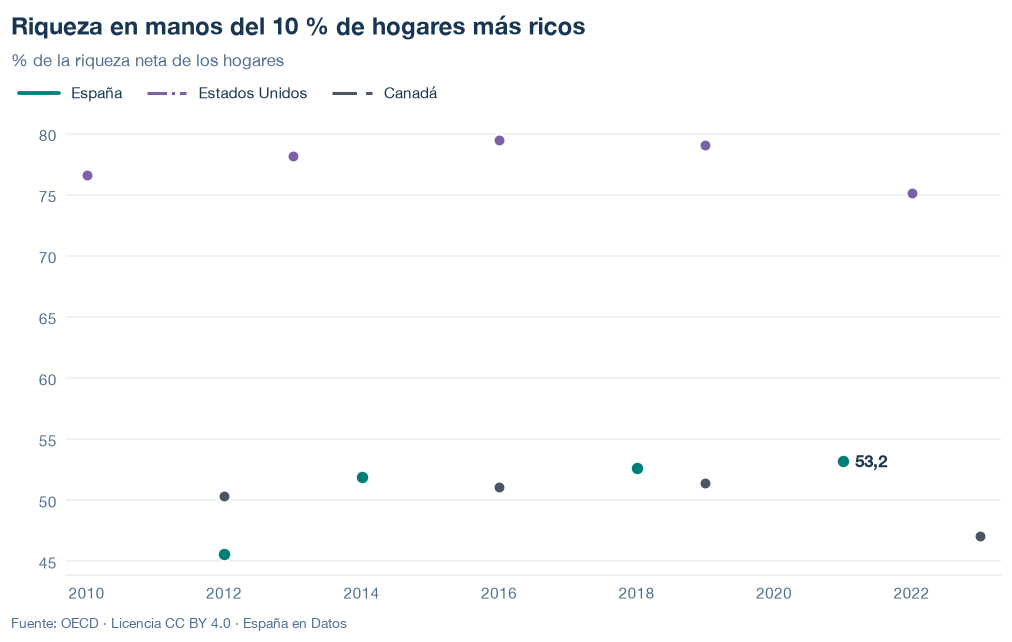

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/concentracion-riqueza.json y data/concentracion-riqueza.csv


## 6. Fuentes, notas y licencia

- OCDE, Wealth Distribution Database: `OECD.WISE.INE,DSD_WEALTH@DF_WEALTH,1.0`, medidas `SH_TOP10`, `SH_TOP5` y `SH_TOP1` (unidad `PT_B90_S14`) de España, EE. UU. y Canadá.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.